In [2]:
!pip install -q fastbook

In [1]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 3050 A Laptop GPU


In [1]:
from fastai.vision.all import *

path = untar_data(URLs.PETS)

def is_cat(x):
    return x[0].isupper()

dls = ImageDataLoaders.from_name_func(
    path/'images',
    get_image_files(path/'images'),
    is_cat,
    item_tfms=Resize(224),
    bs = 32
)

learn = vision_learner(dls, resnet18, metrics=accuracy)
learn.fine_tune(1)

img = get_image_files(path/'images')[0]

pred_class, pred_idx, probabilities = learn.predict(img)

print("Image:", img)
print("Prediction:", pred_class)
print("Class index:", pred_idx)
print("Probabilities:", probabilities)

epoch,train_loss,valid_loss,accuracy,time
0,0.117004,0.033562,0.989175,01:36


epoch,train_loss,valid_loss,accuracy,time
0,0.063493,0.018712,0.993911,01:50


Image: C:\Users\SIDDHANT\.fastai\data\oxford-iiit-pet\images\Abyssinian_1.jpg
Prediction: True
Class index: tensor(1)
Probabilities: tensor([7.6238e-07, 1.0000e+00])


epoch,train_loss,valid_loss,accuracy,time
0,0.122292,0.030421,0.987821,01:54


epoch,train_loss,valid_loss,accuracy,time
0,0.079715,0.029842,0.989175,03:22


Image: C:\Users\SIDDHANT\.fastai\data\oxford-iiit-pet\images\Abyssinian_1.jpg
Prediction: True
Class index: tensor(1)
Probabilities: tensor([4.0730e-04, 9.9959e-01])


epoch,train_loss,valid_loss,accuracy,time
0,0.096403,0.019327,0.992558,02:10


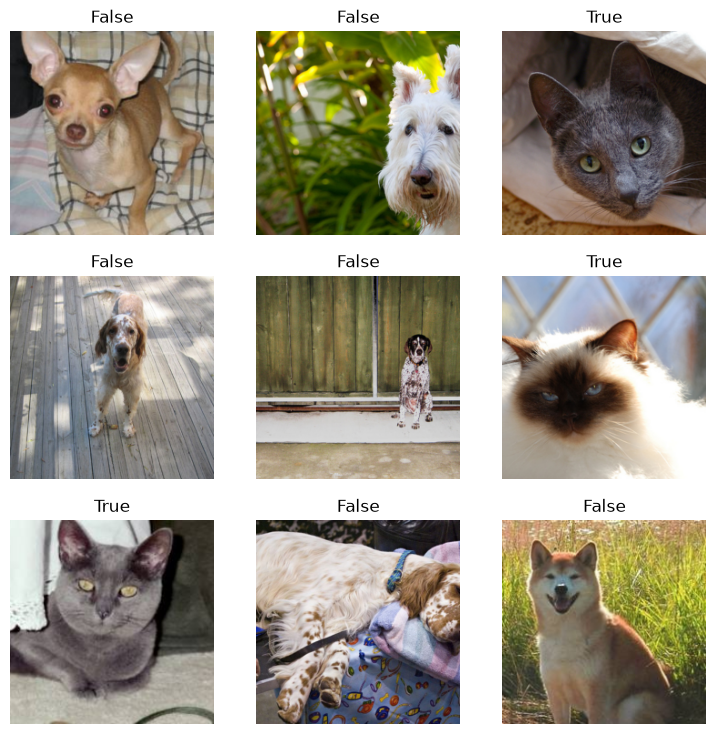

In [2]:
from fastai.vision.all import *

path = untar_data(URLs.PETS)

def is_cat(x):
    return x[0].isupper()

dls = ImageDataLoaders.from_name_func(
    path / "images",
    get_image_files(path / "images"),
    is_cat,
    item_tfms=Resize(224),
    bs=32
)

dls.show_batch()

learn = vision_learner(
    dls,
    resnet18,
    metrics=accuracy
)

learn.fine_tune(1)

img = get_image_files(path/'images')[0]

pred_class, pred_idx, probabilities = learn.predict(img)

print("Image:", img)
print("Prediction:", pred_class)
print("Class index:", pred_idx)
print("Probabilities:", probabilities)

learn2 = vision_learner(
    dls,
    resnet18,
    metrics=accuracy
)

learn2.fit_one_cycle(1, lr_max=1e-3)


epoch,train_loss,valid_loss,accuracy,time
0,0.308474,0.232363,0.928281,01:38
1,0.153933,0.066246,0.975643,01:25
2,0.063498,0.050892,0.985115,01:22


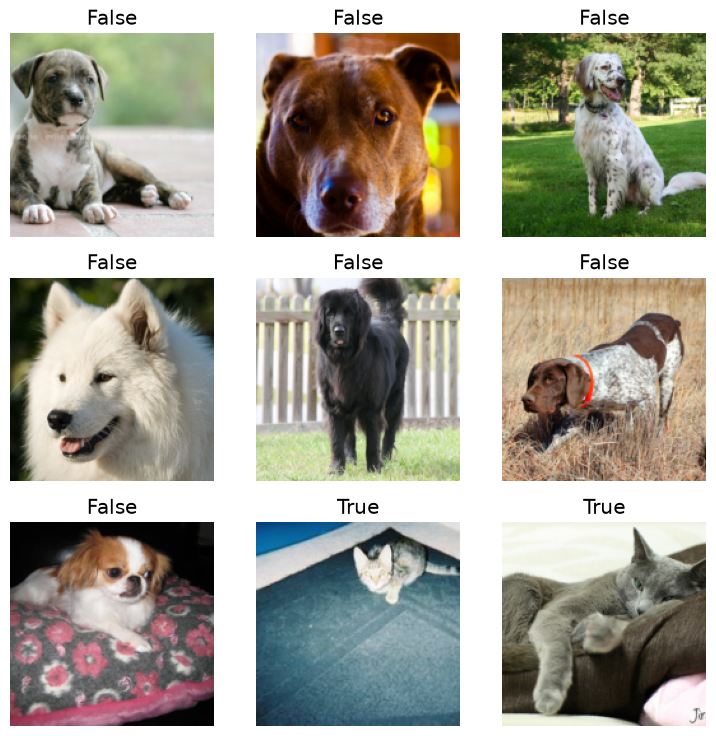

In [1]:
import fastbook
fastbook.setup_book()
from fastbook import *
from fastai.vision.all import *

path = untar_data(URLs.PETS)
files = get_image_files(path/'images')

def is_cat(x):
    return Path(x).name[0].isupper()

dls = ImageDataLoaders.from_name_func(
    path,
    files,
    valid_pct = 0.2,
    seed = 1,
    label_func = is_cat,
    item_tfms=Resize(160)
)

dls.vocab
dls.show_batch()

learn = vision_learner(
    dls,
    resnet18,
    pretrained = True,
    metrics = accuracy
)

learn.model
learn.unfreeze()
learn.fit_one_cycle(3)

In [ ]:
import fastbook
fastbook.setup_book()
from fastbook import *
from fastai.vision.all import *

path = untar_data(URLs.PETS)
files = get_image_files(path/'images')

def is_cat(x):
    return Path(x).name[0].isupper()

dls = ImageDataLoaders.from_name_func(
    path,
    files,
    valid_pct = 0.2,
    seed = 1,
    label_func = is_cat,
    item_tfms=Resize(160)
)

dls.vocab
dls.show_batch()

learn = vision_learner(
    dls,
    resnet18,
    pretrained = True,
    metrics = accuracy
)

learn.model
learn.fit_one_cycle(3)

In [ ]:
import fastbook
fastbook.setup_book()
from fastbook import *
from fastai.vision.all import *

path = untar_data(URLs.PETS)
Path.BASE_PATH = path
(path/'images').ls()

pets = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items = get_image_files,
    splitter = RandomSplitter(seed = 1),
    get_y = using_attr(RegexLabeller(r'(.+)_\d+.jpg$'), "name"),
    item_tfms = Resize(460),
    batch_tfms = aug_transforms(size = 224, min_scale = 0.75)
)

dls = pets.dataloaders(path/'images')
dls.show_batch(nrows=2, ncols=4)



In [ ]:
import torch
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(64 * 109 * 109, 37)
)

print(model)

xb, yb = dls.one_batch()
xb.shape, yb.shape


model = model.to(xb.device)


optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
loss_fn = nn.CrossEntropyLoss()
epochs = 5

for epoch in range(epochs):
    for xb, yb in dls.train:

        optimizer.zero_grad()

        prediction = model(xb)

        loss = loss_fn(prediction.as_subclass(torch.Tensor), yb.as_subclass(torch.Tensor))

        loss.backward()
        optimizer.step()

    print(f'Epoch {epoch + 1}: loss = {loss.item():.4f}')



Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): Flatten(start_dim=1, end_dim=-1)
  (6): Linear(in_features=760384, out_features=37, bias=True)
)
Epoch 1: loss = 3.6122
Epoch 2: loss = 3.5798
Epoch 3: loss = 3.4434
Epoch 4: loss = 3.4461
Epoch 5: loss = 3.5346


In [ ]:
correct = 0
total = 0

xb_val, yb_val = dls.valid.one_batch()
model.eval()

with torch.no_grad():
    for xb, yb in dls.valid:
        prediction = model(xb)

        predicted = prediction.argmax(dim=1)

        predicted = predicted.as_subclass(torch.Tensor)
        yb = yb.as_subclass(torch.Tensor)

        correct += (predicted == yb).sum().item()

        total += yb.size(0)
        

accuracy = correct/total

print(f"Validation Accuracy : {accuracy:.2%}")

Validation Accuracy : 6.02%


In [ ]:
dls_no_aug = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(seed=1),
    get_y=using_attr(RegexLabeller(r'(.+)_\d+.jpg$'), "name"),
    item_tfms=Resize(224)
).dataloaders(path / "images")

xb_no_aug, yb_no_aug = dls_no_aug.one_batch()

print("Images:", xb_no_aug.shape)
print("Labels:", yb_no_aug.shape)

Images: torch.Size([64, 3, 224, 224])
Labels: torch.Size([64])


In [ ]:
model_no_aug = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size = 3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size = 3),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(64 * 109 * 109, 37)
)

model_no_aug = model_no_aug.to(xb_no_aug.device)

In [ ]:
optimizer_no_aug = torch.optim.Adam(model_no_aug.parameters(), lr = 0.001)

epochs = 5

for epoch in range(epochs):
    for xb, yb in dls_no_aug.train:
        optimizer_no_aug.zero_grad()

        prediction = model_no_aug(xb)

        loss = loss_fn(prediction.as_subclass(torch.Tensor), yb.as_subclass(torch.Tensor))

        loss.backward()

        optimizer_no_aug.step()

    print(f"Epoch {epoch+1} : Loss = {loss.item():4f}")

Epoch 1 : Loss = 3.611608
Epoch 2 : Loss = 3.631186
Epoch 3 : Loss = 3.277459
Epoch 4 : Loss = 3.500683
Epoch 5 : Loss = 3.218942


In [ ]:
correct = 0
total = 0

model_no_aug.eval()

with torch.no_grad():
    for xb, yb in dls_no_aug.valid:
        prediction = model_no_aug(xb)

        predicted = prediction.argmax(dim=1)

        predicted = predicted.as_subclass(torch.Tensor)
        yb = yb.as_subclass(torch.Tensor)

        correct += (predicted == yb).sum().item()

        total += yb.size(0)

accuracy_no_aug = correct/total
print(f"No-Augmentation Validation Accuracy: {accuracy_no_aug:.2%}")

No-Augmentation Validation Accuracy: 7.58%


In [ ]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for xb, yb in dls.valid:
        prediction = model(xb)
        predicted = prediction.argmax(dim = 1)

        all_predictions.extend(
            predicted.as_subclass(torch.Tensor).cpu().numpy()
        )
        all_labels.extend(
            yb.as_subclass(torch.Tensor).cpu().numpy()
        )

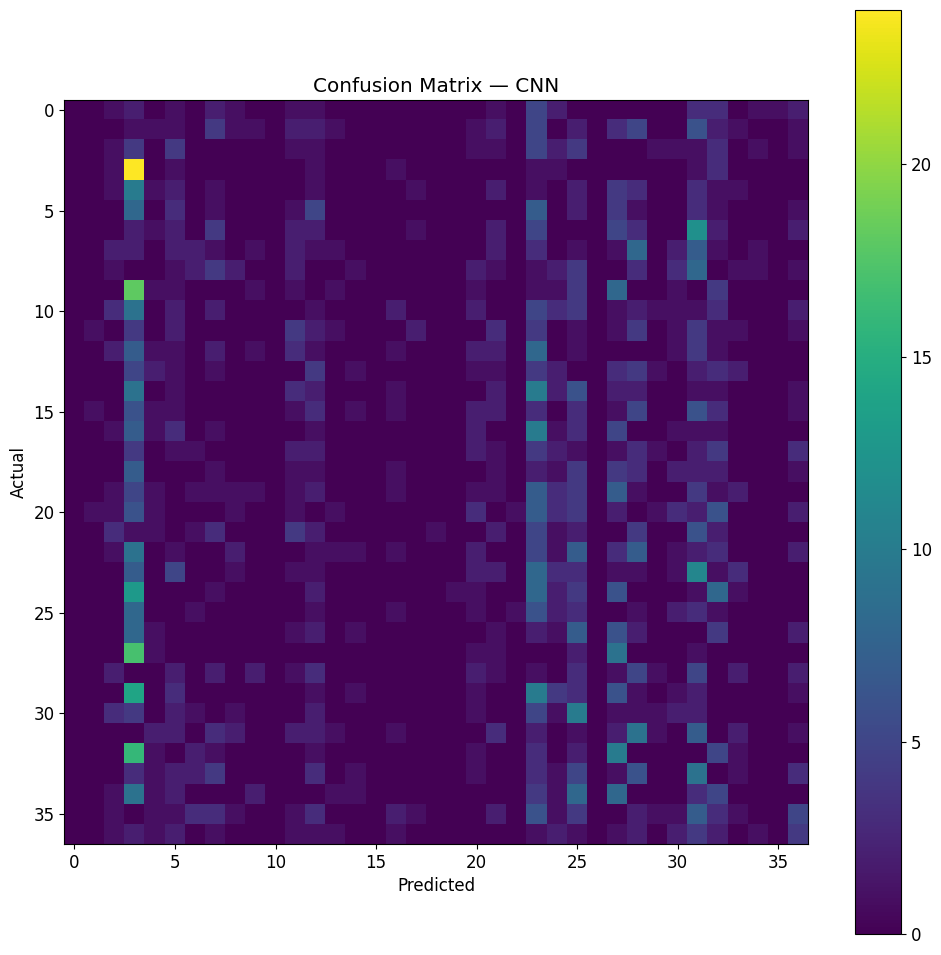

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize = (12, 12))
plt.imshow(cm)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — CNN")
plt.colorbar()
plt.show()

In [ ]:
class_names = dls.vocab

confusions = []

for actual in range(len(class_names)):
    for predicted in range(len(class_names)):

        if actual != predicted:
            confusions.append(
                (
                    cm[actual, predicted],
                    class_names[actual],
                    class_names[predicted]
                )
            )
confusions.sort(reverse=True)

for count, actual, predicted in confusions[:10]:
    print(f'{actual} -> {predicted}: {count}')

Russian_Blue -> Bombay: 18
newfoundland -> Bombay: 17
scottish_terrier -> Bombay: 16
pug -> Bombay: 14
keeshond -> Bombay: 13
Maine_Coon -> samoyed: 12
japanese_chin -> samoyed: 11
scottish_terrier -> newfoundland: 10
saint_bernard -> leonberger: 10
pug -> japanese_chin: 10


epoch,train_loss,valid_loss,error_rate,time


OutOfMemoryError: CUDA out of memory. Tried to allocate 20.00 MiB. GPU 0 has a total capacity of 4.00 GiB of which 0 bytes is free. Of the allocated memory 10.31 GiB is allocated by PyTorch, and 335.42 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

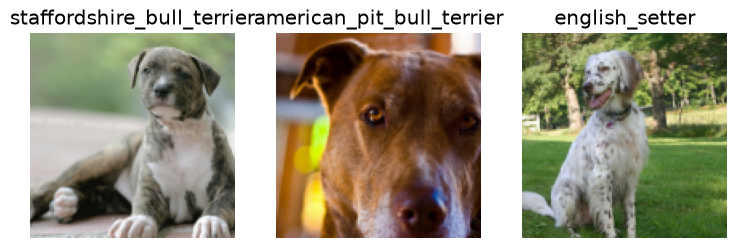

In [1]:
import fastbook
fastbook.setup_book()
from fastbook import *
from fastai.vision.all import *

path = untar_data(URLs.PETS)
Path.BASE_PATH = path
(path/"images").ls()

fname = (path/'images').ls()[0]
re.findall(r'(.+)_\d+.jpg$', fname.name)

pets = DataBlock(blocks = (ImageBlock, CategoryBlock),
                 get_items = get_image_files,
                 splitter = RandomSplitter(seed = 1),
                 get_y = using_attr(RegexLabeller(r'(.+)_\d+.jpg$'), "name"),
                 item_tfms = Resize(460),
                 batch_tfms = aug_transforms(size = 128, min_scale = 0.75))
dls = pets.dataloaders(path/'images', bs = 4)

dls.show_batch(nrows = 1, ncols = 3)


learn = vision_learner(dls, resnet34, metrics = error_rate).to_fp16()
learn.fine_tune(2)

x, y = dls.one_batch()
y

preds, _ = learn.get_preds(dl=[(x,y)])
preds[0]


interp = ClassificationInterpretation.from_learner(learn)
interp.most_confused()

In [1]:
import torch
from torchvision.models import resnet34

model = resnet34(weights="DEFAULT").cuda()

print("Model loaded successfully")
print(f"Allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"Reserved:  {torch.cuda.memory_reserved()/1024**3:.2f} GB")

Model loaded successfully
Allocated: 0.08 GB
Reserved:  0.11 GB


In [4]:
interp = ClassificationInterpretation.from_learner(learn)
interp.most_confused()

[('american_pit_bull_terrier', 'staffordshire_bull_terrier', np.int64(7)),
 ('Ragdoll', 'Birman', np.int64(6)),
 ('staffordshire_bull_terrier', 'american_bulldog', np.int64(6)),
 ('beagle', 'basset_hound', np.int64(5)),
 ('boxer', 'american_bulldog', np.int64(5)),
 ('Bengal', 'Egyptian_Mau', np.int64(4)),
 ('american_pit_bull_terrier', 'american_bulldog', np.int64(4)),
 ('Egyptian_Mau', 'Bengal', np.int64(3)),
 ('Persian', 'Ragdoll', np.int64(3)),
 ('yorkshire_terrier', 'havanese', np.int64(3)),
 ('Abyssinian', 'Siamese', np.int64(2)),
 ('Bengal', 'Maine_Coon', np.int64(2)),
 ('British_Shorthair', 'Russian_Blue', np.int64(2)),
 ('Maine_Coon', 'Bengal', np.int64(2)),
 ('Ragdoll', 'Maine_Coon', np.int64(2)),
 ('Russian_Blue', 'Bombay', np.int64(2)),
 ('american_bulldog', 'staffordshire_bull_terrier', np.int64(2)),
 ('japanese_chin', 'pug', np.int64(2)),
 ('Abyssinian', 'Bengal', np.int64(1)),
 ('Abyssinian', 'Russian_Blue', np.int64(1)),
 ('Bengal', 'Russian_Blue', np.int64(1)),
 ('Birma

In [6]:
results = {
    "Baseline": {
        "valid_loss": 0.024527,
        "accuracy": 0.992640
    },
    "Dropout (p=0.2)": {
        "valid_loss": 0.022137,
        "accuracy": 0.991659
    },
    "Weight decay (wd=0.01)": {
        "valid_loss": 0.023823,
        "accuracy": 0.992640
    }
}

for model, metrics in results.items():
    print(
        f"{model}: "
        f"valid_loss={metrics['valid_loss']:.6f}, "
        f"accuracy={metrics['accuracy']:.4%}"
    )

Baseline: valid_loss=0.024527, accuracy=99.2640%
Dropout (p=0.2): valid_loss=0.022137, accuracy=99.1659%
Weight decay (wd=0.01): valid_loss=0.023823, accuracy=99.2640%


In [5]:
import fastbook
fastbook.setup_book()

from fastai.vision.all import *
from fastbook import *

path = untar_data(URLs.MNIST_SAMPLE)

dls = ImageDataLoaders.from_folder(
    path,
    train='train',
    valid='valid',
    bs = 64
)

xb, yb = dls.one_batch()
# xb.shape, yb.shape

class MLPWeightDecay(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3*28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.net(x)

learn_wd = Learner(
    dls,
    MLPWeightDecay(),
    loss_func= CrossEntropyLossFlat(),
    metrics = accuracy
)


prediction = learn_wd.model.cuda()(xb)
prediction.shape
print(prediction[0])
print(yb[0])


learn_wd.fit_one_cycle(5, 1e-3, wd = 0.01)

TensorImage([ 0.0566, -0.0149], device='cuda:0', grad_fn=<AliasBackward0>)
TensorCategory(1, device='cuda:0')


epoch,train_loss,valid_loss,accuracy,time
0,0.069791,0.052789,0.980864,00:20
1,0.031617,0.037103,0.987242,00:16
2,0.019707,0.032501,0.989696,00:09
3,0.010033,0.023419,0.992149,00:09
4,0.005943,0.023823,0.992640,00:09


In [4]:
import fastbook
fastbook.setup_book()

from fastai.vision.all import *
from fastbook import *

path = untar_data(URLs.MNIST_SAMPLE)

dls = ImageDataLoaders.from_folder(
    path,
    train='train',
    valid='valid',
    bs = 64
)

xb, yb = dls.one_batch()
# xb.shape, yb.shape

class MLPDropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3*28*28, 128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.net(x)

learn_dropout = Learner(
    dls,
    MLPDropout(),
    loss_func= CrossEntropyLossFlat(),
    metrics = accuracy
)


prediction = learn_dropout.model.cuda()(xb)
prediction.shape
print(prediction[0])
print(yb[0])


learn_dropout.fit_one_cycle(5, 1e-3)

TensorImage([0.0856, 0.0604], device='cuda:0', grad_fn=<AliasBackward0>)
TensorCategory(0, device='cuda:0')


epoch,train_loss,valid_loss,accuracy,time
0,0.067141,0.047375,0.984298,00:23
1,0.033784,0.026216,0.988714,00:21
2,0.020609,0.023362,0.991168,00:11
3,0.011039,0.022574,0.992149,00:08
4,0.008279,0.022137,0.991659,00:08


In [1]:
import fastbook
fastbook.setup_book()

from fastai.vision.all import *
from fastbook import *

path = untar_data(URLs.MNIST_SAMPLE)

dls = ImageDataLoaders.from_folder(
    path,
    train='train',
    valid='valid',
    bs = 64
)

xb, yb = dls.one_batch()
# xb.shape, yb.shape

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3*28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.net(x)

learn = Learner(
    dls,
    MLP(),
    loss_func= CrossEntropyLossFlat(),
    metrics = accuracy
)


prediction = learn.model.cuda()(xb)
prediction.shape
print(prediction[0])
print(yb[0])


learn.fit_one_cycle(5, 1e-3)

TensorImage([0.0513, 0.0694], device='cuda:0', grad_fn=<AliasBackward0>)
TensorCategory(0, device='cuda:0')


epoch,train_loss,valid_loss,accuracy,time
0,0.067429,0.052913,0.982826,00:16
1,0.028625,0.031400,0.987242,00:15
2,0.021291,0.023908,0.990677,00:15
3,0.009219,0.024370,0.991659,00:17
4,0.008363,0.024527,0.992640,00:16


torch.Size([6131, 28, 28])
3
tensor(0.1114) tensor(0.2021)
tensor(0.1586) tensor(0.3021)


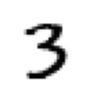

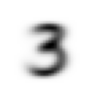

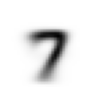

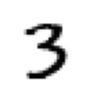

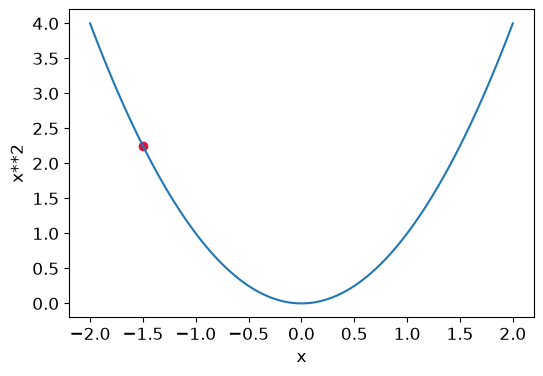

In [9]:
import fastbook
fastbook.setup_book()

from fastai.vision.all import *
from fastbook import *

matplotlib.rc('image', cmap='Greys')

path = untar_data(URLs.MNIST_SAMPLE)

Path.BASE_PATH = path

(path/'train').ls()

threes = (path/'train/3').ls().sorted()
sevens = (path/'train/7').ls().sorted()
threes

im3_path = threes[1]
im3 = Image.open(im3_path)
im3

im3_t = tensor(im3)
df = pd.DataFrame(im3_t[4:15, 4:22])
df.style.set_properties(**{'font-size': '6pt'}).background_gradient('Greys')

three_tensors = [tensor(Image.open(o)) for o in threes]
seven_tensors = [tensor(Image.open(o)) for o in sevens]
# len(three_tensors), len(seven_tensors)

show_image(three_tensors[1]);

stacked_threes = torch.stack(three_tensors).float()/255
stacked_sevens = torch.stack(seven_tensors).float()/255
print(stacked_threes.shape)
print(stacked_threes.ndim)
len(stacked_threes.shape)



mean3 = stacked_threes.mean(0)
show_image(mean3)

mean7 = stacked_sevens.mean(0)
show_image(mean7)



a3 = stacked_threes[1]
show_image(a3)

dist_3_abs = (a3 - mean3).abs().mean()
dist_3_sqr = ((a3 - mean3)**2).mean().sqrt()
print(dist_3_abs, dist_3_sqr)


dist_7_abs = (a3 - mean7).abs().mean()
dist_7_sqr = ((a3 - mean7)**2).mean().sqrt()
print(dist_7_abs, dist_7_sqr)


F.l1_loss(a3.float(), mean7), F.mse_loss(a3, mean7).sqrt()


valid_3_tens = torch.stack([tensor(Image.open(o)) for o in (path/'valid/3').ls()])
valid_3_tens = valid_3_tens.float()/255

valid_7_tens = torch.stack([tensor(Image.open(o)) for o in (path/'valid/7').ls()])
valid_7_tens = valid_7_tens.float()/255

valid_3_tens.shape, valid_7_tens.shape



def mnist_distance(a, b): return (a-b).abs().mean((-1, -2))
mnist_distance(a3, mean3)

valid_3_dist = mnist_distance(valid_3_tens, mean3)
valid_3_dist, valid_3_dist.shape



def is_3 (x): return mnist_distance(x, mean3) < mnist_distance(x, mean7)
is_3(a3), is_3(a3).float()
is_3(valid_3_tens)


accuracy_3 = is_3(valid_3_tens).float().mean()
accuracy_7 = (1 - is_3(valid_7_tens).float().mean())

accuracy_3, accuracy_7, (accuracy_3 + accuracy_7)/2

def f(x): return x**2

plot_function(f, 'x', 'x**2')
plt.scatter(-1.5, f(-1.5), color = 'crimson')

